# 03. 공연–상권 연결과 예비 분석

**질문:** 최신 검증된 시설 상세를 반영하면 주변 공연 활동의 측정 범위가 어떻게 달라지는가?

01번의 기존 상권 격자를 사용하고, 완료된 KOPIS 재수집 스냅샷의 공식 ID·좌표를 반영한다. 시설 연결 → 누락 확인 → EPSG:5181 거리 → 분기 노출 → 두 업종 예비 진단 순서다. 새 연구의 기본 패널과 결과는 **08~10번 외식업 10종**이며, 이 노트북 후반의 두 업종 모형은 연결 갱신에 따른 진단이다. 05번의 과거 기준선은 동결 입력으로 별도 보존한다.

시설명 임시 연결·현재 좌표와 경계의 과거 적용 한계는 남는다. 현재 목록의 좌표 미수집 규모는 아래에서 직접 확인한다. 분석 실행 중 네트워크 요청은 하지 않는다.

In [1]:
from pathlib import Path
import json
import hashlib
import os
from datetime import datetime, timezone
for name in ['OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'OMP_NUM_THREADS']:
    os.environ[name] = '1'
import sys
import platform
import importlib.metadata
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

# 프로젝트 루트 또는 notebooks 폴더에서 실행할 수 있습니다.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'data/raw/seoul_sales').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('졸업프로젝트 폴더 또는 notebooks 폴더에서 실행하세요.')
RAW = ROOT / 'data/raw'
ANALYSIS = ROOT / 'data/analysis'
REPORTS = ROOT / 'reports'
FIGURES = REPORTS / 'figures'
for folder in [ANALYSIS, REPORTS, FIGURES]:
    folder.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_columns', 16)
pd.set_option('display.max_rows', 16)
pd.set_option('display.float_format', lambda value: f'{value:,.3f}')
YEARS = [2023, 2024, 2025]
DISTRICTS = {'11110': '종로구', '11440': '마포구'}
INDUSTRIES = {'CS100001': '한식음식점', 'CS100010': '커피-음료'}
KEY = ['quarter', 'area_id', 'industry_id']
print('프로젝트:', ROOT)
print('Python:', platform.python_version())


프로젝트: C:\Coding\졸업프로젝트
Python: 3.12.14


In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns

DISTRICT_COLORS = {'종로구': '#36688d', '마포구': '#d46b32'}
font_names = {font.name for font in fm.fontManager.ttflist}
font = next((name for name in ['Malgun Gothic', 'NanumGothic', 'AppleGothic'] if name in font_names), 'DejaVu Sans')
sns.set_theme(style='whitegrid', font=font, rc={'axes.unicode_minus': False})
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 160, 'font.size': 10})
path = ANALYSIS / 'sales_stores_panel.csv'
if not path.exists():
    raise FileNotFoundError('먼저 01_데이터_점검과_전처리.ipynb를 실행하세요.')
panel = pd.read_csv(path, dtype={'quarter': str, 'area_id': str, 'industry_id': str})
# 저장 후 다시 읽어도 키와 미제공 매출의 구분이 유지되는지 검사합니다.
assert not panel.duplicated(KEY).any()
assert panel.loc[panel['availability'].isin(['sales_absent', 'both_absent']), 'total_sales'].isna().all()

def save_figure(fig, filename):
    for ax in fig.axes:
        legend = ax.get_legend()
        if legend is not None and legend.get_title().get_text() == 'district':
            legend.set_title('지역')
    fig.tight_layout()
    fig.savefig(FIGURES / filename, bbox_inches='tight')
    plt.show()
    plt.close(fig)

print('분석 패널:', len(panel), '행 / 상권:', panel['area_id'].nunique(), '개')


분석 패널: 3624 행 / 상권: 151 개


## 1. 공연과 시설을 연결하고 근거를 남기기

공연 상세의 공식 `mt10id`를 우선 사용합니다. 나머지는 시설명 완전 일치 또는 ‘시설명(홀명)’의 유일한 접두어 일치로 후보를 정합니다. 공백과 `(폐관)` 표시만 정리하며 비슷한 이름을 강제로 연결하지 않습니다.

`official_detail`만 공식 ID를 직접 확인한 행입니다. 나머지 이름 연결은 검증 대상입니다.


In [3]:
import unicodedata
from collections import defaultdict
KOPIS = ROOT / 'data/processed/kopis'
snapshot_pointer = ROOT / 'metadata/kopis_analysis_sources.json'
collection_snapshot = json.loads(snapshot_pointer.read_text(encoding='utf-8')) if snapshot_pointer.exists() else None
kopis_paths = {
    'performances_list': KOPIS / 'performances_list_seoul_2023_2025.csv',
    'facilities_list': KOPIS / 'facilities_list_seoul.csv',
    'facility_details': KOPIS / 'facilities_detail_seoul.csv',
    'performance_details': KOPIS / 'performances_detail_candidates_2023_2025.csv'}
if collection_snapshot is not None:
    assert collection_snapshot.get('validated') is True, '수집 스냅샷의 검증 완료가 필요합니다.'
    for name in ['facility_details', 'performance_details']:
        record = collection_snapshot['files'][name]
        selected = ROOT / record['path']
        assert hashlib.sha256(selected.read_bytes()).hexdigest() == record['sha256']
        kopis_paths[name] = selected
performances = pd.read_csv(kopis_paths['performances_list'], dtype=str)
facility_list = pd.read_csv(kopis_paths['facilities_list'], dtype=str)
facility_details = pd.read_csv(kopis_paths['facility_details'], dtype=str)
performance_details = pd.read_csv(kopis_paths['performance_details'], dtype=str)
source_provenance = [{'role': name, 'path': path.relative_to(ROOT).as_posix(),
    'sha256': hashlib.sha256(path.read_bytes()).hexdigest(), 'bytes': path.stat().st_size}
    for name, path in kopis_paths.items()]
if collection_snapshot is not None:
    for name, frame in [('facility_details', facility_details), ('performance_details', performance_details)]:
        assert len(frame) == collection_snapshot['files'][name]['rows']
display(pd.DataFrame(source_provenance)[['role', 'path']])
for frame, key in [(performances, 'mt20id'), (facility_list, 'mt10id'),
                   (facility_details, 'mt10id'), (performance_details, 'mt20id')]:
    assert not frame[key].duplicated().any()

def normalize_name(value):
    return '' if pd.isna(value) else ''.join(unicodedata.normalize('NFKC', value).replace('(폐관)', '').split())
name_to_ids = defaultdict(set)
for row in facility_list.itertuples():
    name_to_ids[normalize_name(row.fcltynm)].add(row.mt10id)

def match_name(value):
    name = normalize_name(value)
    if not name:
        return pd.NA, 'unmatched'
    ids = name_to_ids.get(name, set())
    method = 'exact_unique_name'
    if not ids:
        prefixes = [key for key in name_to_ids if key and name.startswith(key + '(')]
        if prefixes:
            ids = name_to_ids[max(prefixes, key=len)]
        method = 'prefix_unique_name'
    if len(ids) == 1:
        return next(iter(ids)), method
    return pd.NA, 'ambiguous' if ids else 'unmatched'

matches = performances['fcltynm'].map(match_name)
performances['name_candidate_id'] = [value[0] for value in matches]
performances['link_method'] = [value[1] for value in matches]
performances['mt10id'] = performances['name_candidate_id'].astype('string')
official_ids = performance_details.set_index('mt20id')['mt10id']
performances['official_id'] = performances['mt20id'].map(official_ids).astype('string')
official = performances['official_id'].notna()
performances['name_official_conflict'] = (official & performances['name_candidate_id'].notna() &
    performances['official_id'].ne(performances['name_candidate_id'])).fillna(False)
performances.loc[official, 'mt10id'] = performances.loc[official, 'official_id']
performances.loc[official, 'link_method'] = 'official_detail'
performances['start_date'] = pd.to_datetime(performances['prfpdfrom'], format='%Y.%m.%d', errors='coerce')
performances['end_date'] = pd.to_datetime(performances['prfpdto'], format='%Y.%m.%d', errors='coerce')
performances['valid_period'] = performances['start_date'].notna() & performances['end_date'].ge(performances['start_date'])
link_summary = performances['link_method'].value_counts().rename_axis('link_method').reset_index(name='performance_ids')
display(link_summary)
print('공식 ID와 이름 후보 불일치:', int(performances['name_official_conflict'].sum()))
print('기간 해석 불가:', int((~performances['valid_period']).sum()))
link_summary.to_csv(REPORTS / 'performance_link_methods.csv', index=False, encoding='utf-8-sig')


,role,path
0,performances_list,data/processed/kopis/performances_list_seoul_2...
1,facilities_list,data/processed/kopis/facilities_list_seoul.csv
2,facility_details,data/analysis/kopis_snapshots/20261004_092358_...
3,performance_details,data/analysis/kopis_snapshots/20261004_092358_...


,link_method,performance_ids
0,exact_unique_name,29099
1,official_detail,948


공식 ID와 이름 후보 불일치: 0
기간 해석 불가: 0


## 2. 좌표 누락은 어느 정도인가?

시설 상세의 위도·경도를 숫자로 변환하고 범위를 확인합니다. 좌표 확보율은 현재 시설 목록 기준이며 과거 위치나 이전 이력을 검증한 것은 아닙니다. 좌표·기간 정보가 부족한 공연은 별도 파일로 남깁니다.


좌표 미수집을 실제 공연 부재로 해석하지 않는다. 수집한 상세 행 수와 유효 좌표를 가진 시설 수를 구분하며, 공식 공연 상세 ID와 이름 임시 연결도 별도 집계한다.

In [4]:
facility_details['longitude'] = pd.to_numeric(facility_details['lo'], errors='coerce')
facility_details['latitude'] = pd.to_numeric(facility_details['la'], errors='coerce')
facility_details['valid_coordinates'] = (facility_details['longitude'].between(124, 132) &
                                         facility_details['latitude'].between(33, 39))
facilities = facility_list.merge(facility_details[['mt10id', 'longitude', 'latitude', 'valid_coordinates', 'adres']],
                                on='mt10id', how='left', validate='one_to_one')
facilities['valid_coordinates'] = facilities['valid_coordinates'].eq(True)
coverage = facilities.groupby('gugunnm', observed=True).agg(
    listed=('mt10id', 'size'), with_coordinates=('valid_coordinates', 'sum'))
coverage['coverage_pct'] = coverage['with_coordinates'] / coverage['listed'] * 100
display(coverage.loc[['종로구', '마포구']])
performances = performances.merge(facilities[['mt10id', 'gugunnm', 'valid_coordinates']],
                                  on='mt10id', how='left', validate='many_to_one')
performances['valid_coordinates'] = performances['valid_coordinates'].eq(True)
performances.to_csv(ANALYSIS / 'performance_facility_linkage.csv', index=False, encoding='utf-8-sig')
unresolved = performances.loc[~performances['valid_coordinates'] | ~performances['valid_period']]
unresolved.to_csv(REPORTS / 'performances_unresolved_for_spatial_analysis.csv', index=False, encoding='utf-8-sig')
coverage.to_csv(REPORTS / 'facility_coordinate_coverage.csv', encoding='utf-8-sig')
print('공연 ID 중 좌표 연결 가능:', int(performances['valid_coordinates'].sum()), '/', len(performances))


,listed,with_coordinates,coverage_pct
gugunnm,,,
종로구,376,376,100.000
마포구,296,296,100.000


공연 ID 중 좌표 연결 가능: 30047 / 30047


## 3. 공연장 점과 상권 폴리곤의 최단거리

시설 좌표를 WGS84 경위도로 해석한 뒤 SHP의 미터 단위 좌표계로 투영합니다. **폴리곤까지의 최단거리**를 사용하며 내부 시설의 거리는 0m입니다.

유효하지 않은 도형은 거리 계산용 사본에 `make_valid`를 적용하고 기록합니다. 원본 파일은 바꾸지 않습니다. 현재 경계와 시설 위치를 모든 분기에 공통 적용하는 한계가 있습니다.


서울시의 2024년 공간단위 변경 공지가 있으므로, 재수집 파일이 기존 파일과 같아도 과거 분기 경계가 동일했다고 해석하지 않는다.

In [5]:
import shapefile
import shapely
from shapely.geometry import shape
from pyproj import CRS, Transformer

boundary_path = next((RAW / 'seoul_areas/extracted').glob('*.shp'))
seoul_pointer = ROOT / 'metadata/seoul_analysis_sources.json'
if seoul_pointer.exists():
    seoul_snapshot = json.loads(seoul_pointer.read_text(encoding='utf-8'))
    assert seoul_snapshot['status'] == 'validated' and seoul_snapshot['validation_passed']
    area_source = next(item for item in seoul_snapshot['items'] if item['dataset'] == 'areas')
    for entry in area_source['extracted']:
        assert hashlib.sha256((ROOT / entry['path']).read_bytes()).hexdigest() == entry['sha256']
        assert entry['same_as_previous'], '경계 변경: 01번 상권 격자와의 구성 검증이 먼저 필요합니다.'
    boundary_path = ROOT / next(entry['path'] for entry in area_source['extracted'] if entry['path'].endswith('.shp'))
reader = shapefile.Reader(str(boundary_path), encoding=boundary_path.with_suffix('.cpg').read_text().strip())
projected_crs = CRS.from_wkt(boundary_path.with_suffix('.prj').read_text())
assert projected_crs.to_epsg() == 5181, '경계 좌표계 변경: 검토 후 실행하세요.'
# ESRI WKT의 축/이름 표기 차이는 EPSG 식별자로 검증하고 계산 축은 x=동쪽, y=북쪽으로 고정합니다.
projected_crs = CRS.from_epsg(5181)
transformer = Transformer.from_crs('EPSG:4326', projected_crs, always_xy=True)
area_geometries, repairs = [], []
for item in reader.iterShapeRecords():
    values = item.record.as_dict()
    district_code = str(values['SIGNGU_CD']).removesuffix('.0')
    if district_code not in DISTRICTS:
        continue
    area_id = str(values['TRDAR_CD']).removesuffix('.0')
    geometry = shape(item.shape.__geo_interface__)
    if not geometry.is_valid:
        reason = shapely.is_valid_reason(geometry)
        geometry = shapely.make_valid(geometry)
        if geometry.geom_type == 'GeometryCollection':
            geometry = shapely.union_all([g for g in geometry.geoms if g.geom_type in ['Polygon', 'MultiPolygon']])
        repairs.append({'area_id': area_id, 'original_problem': reason, 'method': 'make_valid: polygon parts'})
    assert geometry.is_valid and not geometry.is_empty
    area_geometries.append({'area_id': area_id, 'district': DISTRICTS[district_code], 'geometry': geometry})

geo_facilities = facilities.loc[facilities['valid_coordinates']].copy()
geo_facilities['x'], geo_facilities['y'] = transformer.transform(
    geo_facilities['longitude'].to_numpy(), geo_facilities['latitude'].to_numpy())
points = shapely.points(geo_facilities['x'].to_numpy(), geo_facilities['y'].to_numpy())
relations = []
for area in area_geometries:
    distances = shapely.distance(points, area['geometry'])
    for index in np.flatnonzero(distances <= 800):
        relations.append({'area_id': area['area_id'], 'mt10id': geo_facilities.iloc[index]['mt10id'],
                          'distance_m': float(distances[index])})
links = pd.DataFrame(relations)
assert not links.duplicated(['area_id', 'mt10id']).any()
links.to_csv(ANALYSIS / 'venue_area_distances_800m.csv', index=False, encoding='utf-8-sig')
pd.DataFrame(repairs, columns=['area_id', 'original_problem', 'method']).to_csv(
    REPORTS / 'geometry_repairs.csv', index=False, encoding='utf-8-sig')
display(pd.DataFrame([{'거리기준_m': radius, '시설_상권_관계수': int(links['distance_m'].le(radius).sum()),
                       '연결된_시설수': links.loc[links['distance_m'].le(radius), 'mt10id'].nunique()}
                      for radius in [300, 500, 800]]))
print('도형 보정:', len(repairs), '개 / 투영 좌표계:', projected_crs.to_string())

for path in sorted(boundary_path.parent.glob(boundary_path.stem + '.*')):
    source_provenance.append({'role': 'boundary_' + path.suffix.lstrip('.'),
        'path': path.relative_to(ROOT).as_posix(), 'sha256': hashlib.sha256(path.read_bytes()).hexdigest(),
        'bytes': path.stat().st_size})


,거리기준_m,시설_상권_관계수,연결된_시설수
0,300,3049,761
1,500,5670,799
2,800,10493,847


도형 보정: 1 개 / 투영 좌표계: EPSG:5181


## 4. 공간 분포 확인

경계와 시설 점이 같은 좌표계에서 겹치는지 확인합니다. 지도에는 좌표를 확보한 시설만 표시합니다. 두 패널은 각 지역의 위치 확인용으로, 축 범위는 서로 다릅니다.


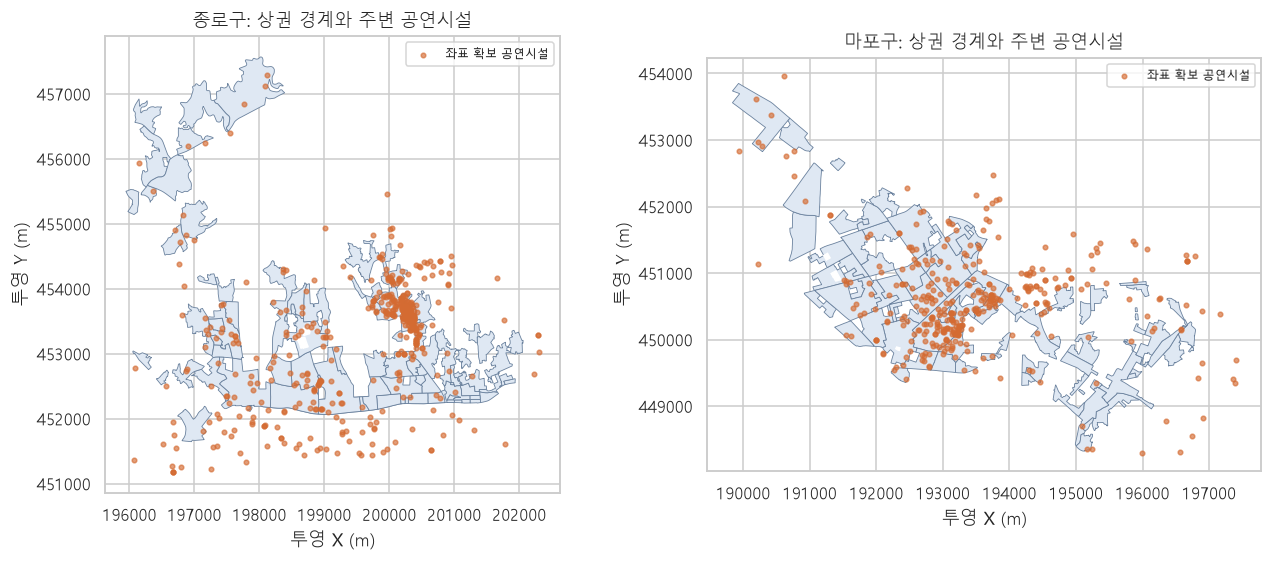

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
for ax, district in zip(axes, DISTRICTS.values()):
    subset = [area for area in area_geometries if area['district'] == district]
    ids = {area['area_id'] for area in subset}
    for area in subset:
        geometry = area['geometry']
        polygons = [geometry] if geometry.geom_type == 'Polygon' else list(geometry.geoms)
        for polygon in polygons:
            x, y = polygon.exterior.xy
            ax.fill(x, y, color='#dfe8f3', edgecolor='#6b829e', linewidth=0.55)
            for ring in polygon.interiors:
                x, y = ring.xy
                ax.fill(x, y, color='white')
    nearby_ids = links.loc[links['area_id'].isin(ids), 'mt10id'].unique()
    located = geo_facilities.loc[geo_facilities['mt10id'].isin(nearby_ids)]
    ax.scatter(located['x'], located['y'], s=9, color='#d46b32', alpha=0.65, label='좌표 확보 공연시설')
    ax.set_title(f'{district}: 상권 경계와 주변 공연시설')
    ax.set_aspect('equal'); ax.set_xlabel('투영 X (m)'); ax.set_ylabel('투영 Y (m)')
    ax.ticklabel_format(style='plain', useOffset=False); ax.legend(loc='best', fontsize=8)
save_figure(fig, '05_venues_and_areas.png')


## 5. 분기별 ‘관측된 등록 공연 수’ 만들기

공연 기간과 분기가 하루라도 겹치면 해당 분기에 공연 ID를 포함합니다. 한 상권·분기 안에서는 같은 ID를 한 번만 셉니다. 장기 공연은 여러 분기에 반복됩니다.

`known_performance_count_*m`는 **좌표가 확보되고 연결된 시설에서 관측된 공연 ID 수**입니다. 여기의 0은 관측된 공연이 없다는 뜻이며 실제 공연 0건을 보장하지 않습니다. 공연 기간 중 매일 상연했다고 가정하지 않습니다.


In [7]:
quarter_rows = []
for year in YEARS:
    for number in range(1, 5):
        period = pd.Period(f'{year}Q{number}', freq='Q')
        quarter_rows.append({'quarter': f'{year}{number}', 'start': period.start_time, 'end': period.end_time})
quarter_table = pd.DataFrame(quarter_rows)
usable = performances.loc[performances['valid_coordinates'] & performances['valid_period']].copy()
active_rows = []
for q in quarter_table.itertuples():
    selected = usable.loc[usable['start_date'].le(q.end) & usable['end_date'].ge(q.start),
                          ['mt20id', 'mt10id', 'link_method']].copy()
    selected['quarter'] = q.quarter
    active_rows.append(selected)
active = pd.concat(active_rows, ignore_index=True)
assert not active.duplicated(['mt20id', 'quarter']).any()
active.to_csv(ANALYSIS / 'performance_facility_quarter.csv', index=False, encoding='utf-8-sig')
area_quarters = panel[['area_id', 'quarter']].drop_duplicates().copy()
for radius in [300, 500, 800]:
    near = links.loc[links['distance_m'].le(radius), ['area_id', 'mt10id']]
    nearby_active = active.merge(near, on='mt10id', how='inner', validate='many_to_many')
    counts = nearby_active.groupby(['area_id', 'quarter'], observed=True)['mt20id'].nunique()
    column = f'known_performance_count_{radius}m'
    area_quarters = area_quarters.merge(counts.rename(column), on=['area_id', 'quarter'], how='left', validate='one_to_one')
    # 확보한 시설의 관측 건수 열에만 0을 채웁니다. 매출에는 적용하지 않습니다.
    area_quarters[column] = area_quarters[column].fillna(0).astype(int)
combined = panel.merge(area_quarters, on=['area_id', 'quarter'], how='left', validate='many_to_one')
assert len(combined) == len(panel) and not combined.duplicated(KEY).any()
assert combined.loc[combined['availability'].isin(['sales_absent', 'both_absent']), 'total_sales'].isna().all()
area_quarters.to_csv(ANALYSIS / 'area_performance_quarter.csv', index=False, encoding='utf-8-sig')
combined.to_csv(ANALYSIS / 'performance_sales_panel.csv', index=False, encoding='utf-8-sig')
display(combined[['known_performance_count_300m', 'known_performance_count_500m', 'known_performance_count_800m']].describe())

# 갱신 전 노출과의 차이는 원자료 변경과 구분하여 남깁니다.
baseline_path = ANALYSIS / 'baseline_two_industry/performance_sales_panel.csv'
old_exposure = pd.read_csv(baseline_path, dtype={'area_id': str, 'quarter': str})
exposure_columns = [f'known_performance_count_{radius}m' for radius in [300, 500, 800]]
old_exposure = old_exposure[['area_id', 'quarter', *exposure_columns]].drop_duplicates()
exposure_revision = area_quarters.merge(old_exposure, on=['area_id', 'quarter'],
    suffixes=('_current', '_baseline'), validate='one_to_one')
for column in exposure_columns:
    exposure_revision[column + '_difference'] = exposure_revision[column + '_current'] - exposure_revision[column + '_baseline']
exposure_revision.to_csv(REPORTS / '03_exposure_revisions.csv', index=False, encoding='utf-8-sig')
display(pd.DataFrame([{'radius_m': radius,
    'changed_area_quarters': int(exposure_revision[f'known_performance_count_{radius}m_difference'].ne(0).sum()),
    'largest_increase': int(exposure_revision[f'known_performance_count_{radius}m_difference'].max()),
    'largest_decrease': int(exposure_revision[f'known_performance_count_{radius}m_difference'].min())}
    for radius in [300, 500, 800]]))


,known_performance_count_300m,known_performance_count_500m,known_performance_count_800m
count,"3,624.000","3,624.000","3,624.000"
mean,27.389,57.039,106.742
std,63.061,94.660,129.993
min,0.000,0.000,0.000
25%,0.000,1.000,13.000
50%,3.000,15.000,46.000
75%,23.000,59.000,163.250
max,586.000,627.000,675.000


,radius_m,changed_area_quarters,largest_increase,largest_decrease
0,300,164,33,0
1,500,231,33,0
2,800,395,34,0


## 6. 공연 수와 매출의 분포를 함께 보기

점 하나는 상권×분기입니다. 규모가 큰 상권에 공연장과 음식점이 함께 많을 수 있으므로 산점도의 기울기를 효과로 해석하지 않습니다. 0을 포함하기 위해 양쪽 축은 `log(1+x)`로 변환합니다.


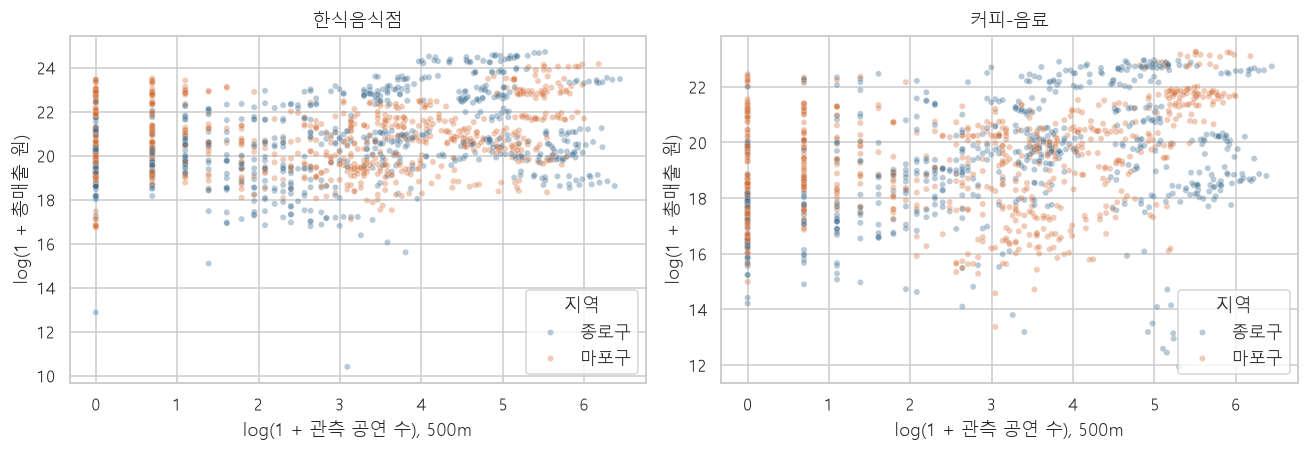

In [8]:
scatter = combined.loc[combined['total_sales'].ge(0) & ~combined['negative_sales_flag']].copy()
scatter['log_activity'] = np.log1p(scatter['known_performance_count_500m'])
scatter['log_sales'] = np.log1p(scatter['total_sales'])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, industry in zip(axes, INDUSTRIES.values()):
    sns.scatterplot(data=scatter.loc[scatter['industry'].eq(industry)], x='log_activity', y='log_sales',
                    hue='district', palette=DISTRICT_COLORS, hue_order=list(DISTRICTS.values()), s=16, alpha=0.35, ax=ax)
    ax.set_title(industry); ax.set_xlabel('log(1 + 관측 공연 수), 500m'); ax.set_ylabel('log(1 + 총매출 원)')
save_figure(fig, '06_performances_and_sales.png')


## 7. 업종별 패널 회귀와 거리 기준 점검

각 업종을 따로 분석하고 **상권 고정효과 + 연도분기 고정효과**를 사용합니다. 업종별로 나누므로 업종마다 다른 시간 변화와 상권 특성을 허용합니다. 표준오차는 상권 단위로 군집화합니다.

- 설명변수: `log(1 + 관측 공연 수)`와 `log(1 + 점포 수)`.
- 결과변수: `log(1 + 총매출)` 또는 야간 매출 비중(%).
- 500m가 기본이며 300m·800m도 비교합니다.
- 필요한 값이 관측되고 유효한 행만 사용합니다. 미제공 매출을 채우지 않습니다.

고정효과를 넣어도 공연 입지 선택, 유동인구, 미수집 공연 등은 남습니다. **부분 수집 자료의 관련성 점검**이며 계수의 유의성만으로 결론을 정하지 않습니다. 설계행렬의 열이 서로 종속되어 계수를 구분할 수 없으면 `rank_deficient`로 표시합니다.


12개 모형의 p값은 다중검정 보정을 하지 않았으므로 탐색용으로만 해석합니다.


In [9]:
import statsmodels.formula.api as smf

model_rows = []
for industry in INDUSTRIES.values():
    for radius in [300, 500, 800]:
        for outcome in ['log_sales', 'night_share_pct']:
            frame = combined.loc[combined['industry'].eq(industry)].copy()
            frame = frame.loc[frame['total_sales'].ge(0) & frame['store_count'].ge(0) &
                              ~frame['negative_sales_flag'] & ~frame['negative_store_flag']].copy()
            frame['log_activity'] = np.log1p(frame[f'known_performance_count_{radius}m'])
            frame['log_stores'] = np.log1p(frame['store_count'])
            frame['log_sales'] = np.log1p(frame['total_sales'])
            frame['night_share_pct'] = frame['night_share'] * 100
            frame = frame.dropna(subset=[outcome, 'log_activity', 'log_stores', 'area_id', 'quarter'])
            # 한 번만 관측된 상권은 상권 내 시간 변화를 설명할 수 없어 제외합니다.
            frame = frame.loc[frame.groupby('area_id')['quarter'].transform('nunique').ge(2)].copy()
            base_record = {'industry': industry, 'radius_m': radius, 'outcome': outcome,
                           'nobs': len(frame), 'area_clusters': frame['area_id'].nunique(),
                           'sample_excluded_rows': int(combined['industry'].eq(industry).sum() - len(frame))}
            if frame['area_id'].nunique() < 10 or frame['log_activity'].nunique() < 2:
                model_rows.append(dict(base_record, status='insufficient_sample'))
                continue
            model = smf.ols(f'{outcome} ~ log_activity + log_stores + C(area_id) + C(quarter)', data=frame).fit(
                cov_type='cluster', cov_kwds={'groups': frame['area_id']}, use_t=True)
            if np.linalg.matrix_rank(model.model.exog) < model.model.exog.shape[1]:
                model_rows.append(dict(base_record, status='rank_deficient'))
                continue
            interval = model.conf_int().loc['log_activity']
            model_rows.append(dict(base_record, status='estimated', coefficient=model.params['log_activity'],
                                   standard_error=model.bse['log_activity'], ci_low=interval.iloc[0], ci_high=interval.iloc[1],
                                   p_value=model.pvalues['log_activity']))
results = pd.DataFrame(model_rows)
results.to_csv(REPORTS / 'panel_regression_results.csv', index=False, encoding='utf-8-sig')
display(results.loc[results['radius_m'].eq(500)].round(4))
print('표의 95% 신뢰구간은 상권 군집 표준오차를 사용했습니다.')


,industry,radius_m,outcome,nobs,area_clusters,sample_excluded_rows,status,coefficient,standard_error,ci_low,ci_high,p_value
2,한식음식점,500,log_sales,1488,126,324,estimated,-0.013,0.035,-0.083,0.056,0.700
3,한식음식점,500,night_share_pct,1488,126,324,estimated,-0.593,0.242,-1.071,-0.114,0.016
8,커피-음료,500,log_sales,1307,115,505,estimated,-0.005,0.048,-0.100,0.090,0.917
9,커피-음료,500,night_share_pct,1307,115,505,estimated,-0.084,0.235,-0.549,0.381,0.721


표의 95% 신뢰구간은 상권 군집 표준오차를 사용했습니다.


## 8. 거리 변경에 따른 계수 비교

점은 공연 수 변환 변수의 계수, 선은 95% 신뢰구간입니다. 왼쪽은 로그 총매출, 오른쪽은 야간 비중의 **퍼센트포인트** 단위로 두 계수의 크기를 직접 비교하지 않습니다.

거리 기준에 따라 부호나 구간이 달라지면 측정 범위에 민감하다는 점부터 확인합니다. 이 그래프는 최종적인 효과 입증 자료가 아닙니다.


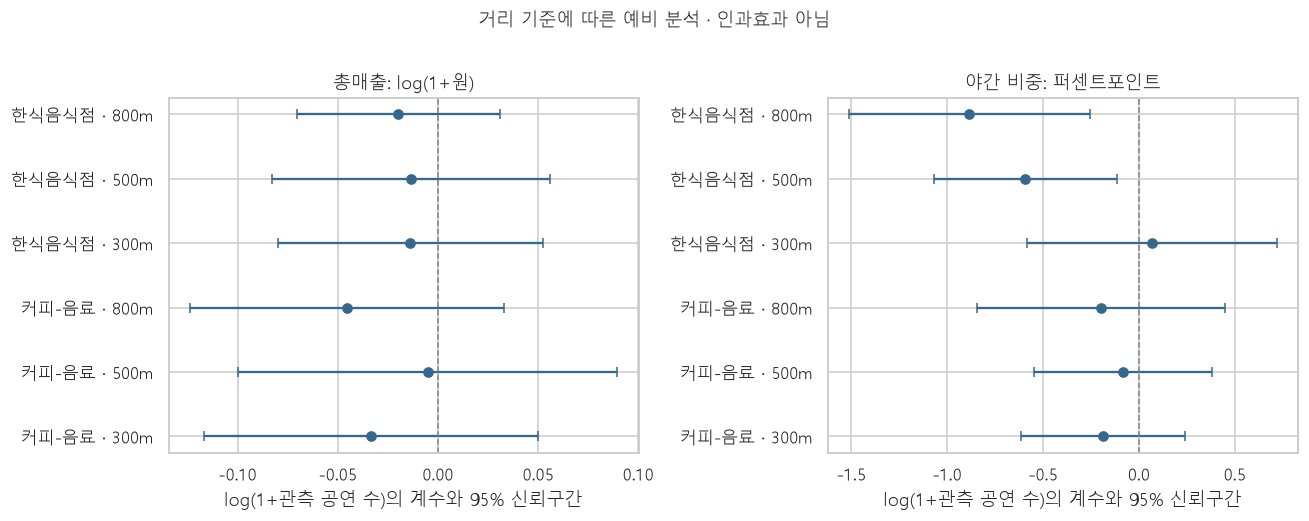

**해석 범위:** 공연 30,047개 중 좌표 연결 가능 30,047개, 공식 상세 ID 직접 확인 948개입니다. 좌표 확보는 현재 시설 목록 기준입니다. 이름 임시 연결의 공식 ID 검증과 과거 시설 위치·경계 검증이 남아 있으므로 인과효과로 확정하지 않습니다.

In [10]:
estimated = results.loc[results['status'].eq('estimated')].copy()
if not estimated.empty:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
    outcome_labels = {'log_sales': '총매출: log(1+원)', 'night_share_pct': '야간 비중: 퍼센트포인트'}
    for ax, outcome in zip(axes, outcome_labels):
        subset = estimated.loc[estimated['outcome'].eq(outcome)].sort_values(['industry', 'radius_m'])
        positions = np.arange(len(subset))
        ax.errorbar(subset['coefficient'], positions,
                    xerr=np.vstack([subset['coefficient'] - subset['ci_low'], subset['ci_high'] - subset['coefficient']]),
                    fmt='o', capsize=3, color='#36688d')
        ax.set_yticks(positions, [f'{r.industry} · {r.radius_m}m' for r in subset.itertuples()])
        ax.axvline(0, color='grey', lw=1, ls='--'); ax.set_title(outcome_labels[outcome])
        ax.set_xlabel('log(1+관측 공연 수)의 계수와 95% 신뢰구간')
    fig.suptitle('거리 기준에 따른 예비 분석 · 인과효과 아님', y=1.02)
    save_figure(fig, '07_regression_distance_sensitivity.png')
else:
    display(Markdown('식별 가능한 회귀가 없어 계수 그림을 만들지 않았습니다. 결과표의 status를 확인하세요.'))
summary = {'created_utc': datetime.now(timezone.utc).isoformat(),
           'collection_run_id': collection_snapshot['run_id'] if collection_snapshot else None,
           'collection_status': collection_snapshot['status'] if collection_snapshot else 'legacy_processed',
           'source_files': source_provenance,
           'facility_detail_rows': len(facility_details), 'performance_detail_rows': len(performance_details),
           'coordinate_reference_system': 'EPSG:5181',
           'distance_definition': 'minimum_Euclidean_distance_from_facility_point_to_current_area_polygon',
           'performance_period_source': 'stored_2023_2025_monthly_list_not_latest_detail_dates',
           'network_requests': 0,
           'performance_ids': len(performances), 'official_link_ids': int(official.sum()),
           'performance_ids_with_coordinates': int(performances['valid_coordinates'].sum()),
           'unresolved_performance_ids': len(unresolved), 'venue_area_relations': len(links),
           'changed_500m_area_quarters': int(exposure_revision['known_performance_count_500m_difference'].ne(0).sum()),
           'provisional_name_link_ids': int(performances['link_method'].isin(['exact_unique_name', 'prefix_unique_name']).sum()),
           'panel_rows': len(combined), 'estimated_models': len(estimated),
           'facility_ids_with_coordinates': int(facilities['valid_coordinates'].sum()),
           'facility_ids_without_coordinates': int((~facilities['valid_coordinates']).sum()),
           'classification': 'preliminary_association_with_provisional_links_and_unverified_historical_locations'}
pd.DataFrame(source_provenance).to_csv(REPORTS / '03_input_sources.csv', index=False, encoding='utf-8-sig')
for record in source_provenance:
    assert hashlib.sha256((ROOT / record['path']).read_bytes()).hexdigest() == record['sha256']
(REPORTS / 'linkage_analysis_summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
display(Markdown(f"**해석 범위:** 공연 {len(performances):,}개 중 좌표 연결 가능 {summary['performance_ids_with_coordinates']:,}개, "
                 f"공식 상세 ID 직접 확인 {summary['official_link_ids']:,}개입니다. "
                 '좌표 확보는 현재 시설 목록 기준입니다. 이름 임시 연결의 공식 ID 검증과 과거 시설 위치·경계 검증이 남아 있으므로 인과효과로 확정하지 않습니다.'))
